In [1]:
 !pip install nltk wordcloud --user

In [2]:

import nltk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("All libraries loaded!")


[nltk_data] Downloading package punkt to C:\Users\i5
[nltk_data]     74h\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\i5
[nltk_data]     74h\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\i5
[nltk_data]     74h\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\i5
[nltk_data]     74h\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\i5
[nltk_data]     74h\AppData\Roaming\nltk_data...


All libraries loaded!


[nltk_data]   Package omw-1.4 is already up-to-date!


In [3]:

data = {
    'headline': [
        "OGDC reports record profits this quarter",
        "HBL stock crashes after bad earnings report",
        "Pakistan economy growing at fastest pace",
        "Inflation hits record high in Pakistan",
        "LUCK cement sees massive increase in exports",
        "PSX market falls due to political uncertainty",
        "ENGRO fertilizer profits up by 30 percent",
        "Interest rates raised causing stock market drop",
        "Oil prices surge benefiting OGDC shareholders",
        "Banking sector faces losses amid economic crisis",
        "PSX hits all time high record today",
        "Foreign investment declining in Pakistan market",
        "Lucky cement wins major government contract",
        "HBL expands operations to new countries",
        "Stock market recovers after positive news",
        "Rupee depreciation hurts import companies",
        "OGDC discovers new oil reserves in Balochistan",
        "Market crashes on negative economic outlook",
        "Pakistan GDP growth exceeds expectations",
        "Energy crisis impacts manufacturing sector badly",
        "Strong earnings boost investor confidence",
        "Company reports massive losses this year",
        "New investment brings hope to Pakistan economy",
        "Strike shuts down major factory operations",
        "Stock prices rise on positive government policy",
        "Debt crisis threatens economic stability",
        "Record exports drive Pakistan trade surplus",
        "Power outages damage industrial production",
        "Foreign reserves increase to record levels",
        "Unemployment rate rises sharply in Pakistan",
        "OGDC signs billion dollar deal with partners",
        "HBL faces regulatory penalty from authorities",
        "Pakistan receives major IMF loan approval",
        "Floods destroy crops causing food shortage",
        "Tech sector booming with new startups",
        "Political instability scares away investors",
        "LUCK cement exports reach new markets globally",
        "Factory closures lead to job losses",
        "Dividend payouts increase for shareholders",
        "Currency devaluation hits purchasing power",
        "PSX gains two percent on positive data",
        "Oil import bill rises causing deficit",
        "ENGRO announces expansion of new plant",
        "Wheat shortage pushes food prices higher",
        "Remittances from overseas reach record high",
        "Trade deficit widens hurting Pakistan economy",
        "HBL profit doubles in second quarter",
        "Natural disaster disrupts supply chains badly",
        "Pakistan wins major infrastructure investment",
        "Rising costs squeeze company profit margins"
    ],
    'sentiment': [
        'positive','negative','positive','negative','positive',
        'negative','positive','negative','positive','negative',
        'positive','negative','positive','positive','positive',
        'negative','positive','negative','positive','negative',
        'positive','negative','positive','negative','positive',
        'negative','positive','negative','positive','negative',
        'positive','negative','positive','negative','positive',
        'negative','positive','negative','positive','negative',
        'positive','negative','positive','negative','positive',
        'negative','positive','negative','positive','negative'
    ]
}

df = pd.DataFrame(data)
df.to_csv('financial_news.csv', index=False)
print("Dataset created and saved!")
print("Shape:", df.shape)
print("Sentiment counts:\n", df['sentiment'].value_counts())
print(df.head(10))


Dataset created and saved!
Shape: (50, 2)
Sentiment counts:
 sentiment
positive    26
negative    24
Name: count, dtype: int64
                                           headline sentiment
0          OGDC reports record profits this quarter  positive
1       HBL stock crashes after bad earnings report  negative
2          Pakistan economy growing at fastest pace  positive
3            Inflation hits record high in Pakistan  negative
4      LUCK cement sees massive increase in exports  positive
5     PSX market falls due to political uncertainty  negative
6         ENGRO fertilizer profits up by 30 percent  positive
7   Interest rates raised causing stock market drop  negative
8     Oil prices surge benefiting OGDC shareholders  positive
9  Banking sector faces losses amid economic crisis  negative


In [4]:

import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['cleaned'] = df['headline'].apply(clean_text)
print("Data Cleaning Complete!")
print("\nOriginal vs Cleaned:")
for i in range(3):
    print(f"Original : {df['headline'][i]}")
    print(f"Cleaned  : {df['cleaned'][i]}")
    print()


Data Cleaning Complete!

Original vs Cleaned:
Original : OGDC reports record profits this quarter
Cleaned  : ogdc reports record profits this quarter

Original : HBL stock crashes after bad earnings report
Cleaned  : hbl stock crashes after bad earnings report

Original : Pakistan economy growing at fastest pace
Cleaned  : pakistan economy growing at fastest pace



In [5]:

from nltk.tokenize import word_tokenize

df['tokens'] = df['cleaned'].apply(word_tokenize)
print("Tokenization Complete!")
print("\nExample tokens:")
for i in range(3):
    print(f"Headline : {df['cleaned'][i]}")
    print(f"Tokens   : {df['tokens'][i]}")
    print()


Tokenization Complete!

Example tokens:
Headline : ogdc reports record profits this quarter
Tokens   : ['ogdc', 'reports', 'record', 'profits', 'this', 'quarter']

Headline : hbl stock crashes after bad earnings report
Tokens   : ['hbl', 'stock', 'crashes', 'after', 'bad', 'earnings', 'report']

Headline : pakistan economy growing at fastest pace
Tokens   : ['pakistan', 'economy', 'growing', 'at', 'fastest', 'pace']



In [6]:

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

def remove_stopwords(tokens):
    return [w for w in tokens if w not in stop_words]

df['tokens_clean'] = df['tokens'].apply(remove_stopwords)
print("Stopword Removal Complete!")
print("\nBefore vs After stopword removal:")
for i in range(3):
    print(f"Before : {df['tokens'][i]}")
    print(f"After  : {df['tokens_clean'][i]}")
    print()


Stopword Removal Complete!

Before vs After stopword removal:
Before : ['ogdc', 'reports', 'record', 'profits', 'this', 'quarter']
After  : ['ogdc', 'reports', 'record', 'profits', 'quarter']

Before : ['hbl', 'stock', 'crashes', 'after', 'bad', 'earnings', 'report']
After  : ['hbl', 'stock', 'crashes', 'bad', 'earnings', 'report']

Before : ['pakistan', 'economy', 'growing', 'at', 'fastest', 'pace']
After  : ['pakistan', 'economy', 'growing', 'fastest', 'pace']



In [7]:

from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

def lemmatize_tokens(tokens):
    return [lemmatizer.lemmatize(w) for w in tokens]

df['lemmatized']     = df['tokens_clean'].apply(lemmatize_tokens)
df['processed_text'] = df['lemmatized'].apply(lambda x: ' '.join(x))

print("Lemmatization Complete!")
print("\nBefore vs After lemmatization:")
for i in range(3):
    print(f"Before : {df['tokens_clean'][i]}")
    print(f"After  : {df['lemmatized'][i]}")
    print()


Lemmatization Complete!

Before vs After lemmatization:
Before : ['ogdc', 'reports', 'record', 'profits', 'quarter']
After  : ['ogdc', 'report', 'record', 'profit', 'quarter']

Before : ['hbl', 'stock', 'crashes', 'bad', 'earnings', 'report']
After  : ['hbl', 'stock', 'crash', 'bad', 'earnings', 'report']

Before : ['pakistan', 'economy', 'growing', 'fastest', 'pace']
After  : ['pakistan', 'economy', 'growing', 'fastest', 'pace']



In [8]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=50)
X     = tfidf.fit_transform(df['processed_text'])

print("TF-IDF Vectorization Complete!")
print("Matrix Shape:", X.shape)
print("\nTop 20 features (words):")
print(tfidf.get_feature_names_out()[:20])

tfidf_df = pd.DataFrame(X.toarray(), columns=tfidf.get_feature_names_out())
print(tfidf_df.head())


TF-IDF Vectorization Complete!
Matrix Shape: (50, 50)

Top 20 features (words):
['badly' 'causing' 'cement' 'company' 'crash' 'crisis' 'deficit'
 'earnings' 'economic' 'economy' 'engro' 'export' 'face' 'factory' 'food'
 'foreign' 'government' 'hbl' 'high' 'hit']
   badly  causing    cement  company     crash  crisis  deficit  earnings  \
0    0.0      0.0  0.000000      0.0  0.000000     0.0      0.0  0.000000   
1    0.0      0.0  0.000000      0.0  0.479023     0.0      0.0  0.479023   
2    0.0      0.0  0.000000      0.0  0.000000     0.0      0.0  0.000000   
3    0.0      0.0  0.000000      0.0  0.000000     0.0      0.0  0.000000   
4    0.0      0.0  0.432835      0.0  0.000000     0.0      0.0  0.000000   

   economic   economy  ...  psx   quarter  rate  reach    record    report  \
0       0.0  0.000000  ...  0.0  0.502216   0.0    0.0  0.391206  0.464525   
1       0.0  0.000000  ...  0.0  0.000000   0.0    0.0  0.000000  0.443072   
2       0.0  0.813581  ...  0.0  0.00000

In [9]:

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y = (df['sentiment'] == 'positive').astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf     = LogisticRegression()
clf.fit(X_train, y_train)
y_pred  = clf.predict(X_test)

print("Text Classification Complete!")
print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))


Text Classification Complete!

Accuracy: 0.90

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      0.80      0.89         5
    Positive       0.83      1.00      0.91         5

    accuracy                           0.90        10
   macro avg       0.92      0.90      0.90        10
weighted avg       0.92      0.90      0.90        10



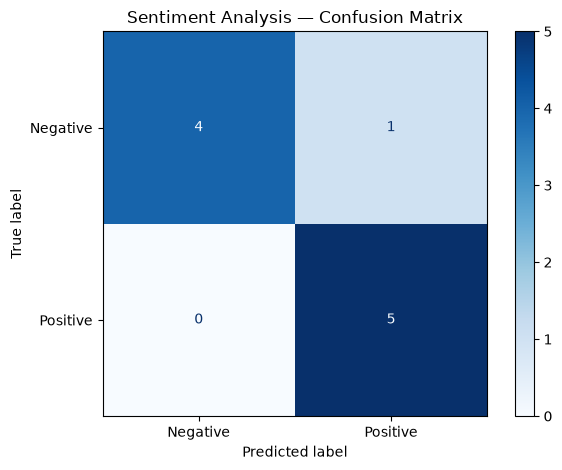

In [10]:

from sklearn.metrics import ConfusionMatrixDisplay

cm   = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['Negative', 'Positive'])
disp.plot(cmap='Blues')
plt.title("Sentiment Analysis — Confusion Matrix")
plt.tight_layout()
plt.show()


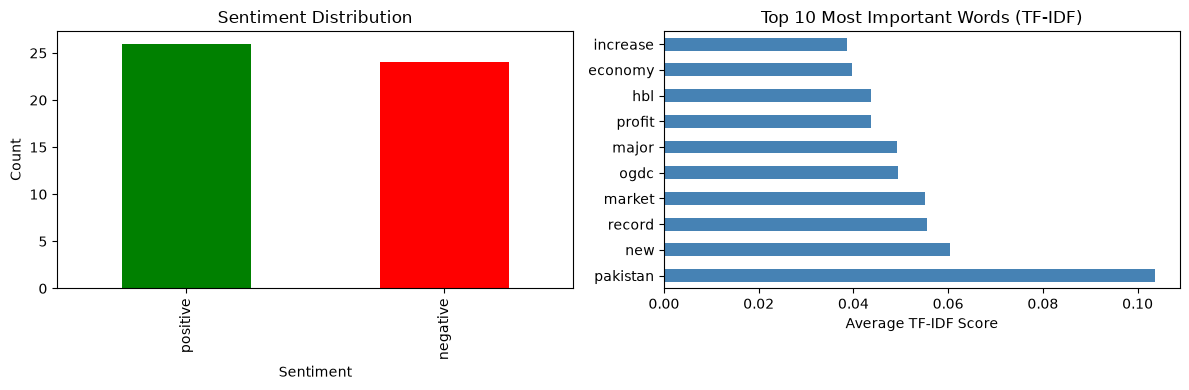

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['sentiment'].value_counts().plot(
    kind='bar', ax=axes[0], color=['green', 'red'])
axes[0].set_title("Sentiment Distribution")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Count")

mean_tfidf = tfidf_df.mean().sort_values(ascending=False).head(10)
mean_tfidf.plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title("Top 10 Most Important Words (TF-IDF)")
axes[1].set_xlabel("Average TF-IDF Score")

plt.tight_layout()
plt.show()


In [12]:

def predict_sentiment(text):
    cleaned   = clean_text(text)
    tokens    = word_tokenize(cleaned)
    no_stop   = remove_stopwords(tokens)
    lemmed    = lemmatize_tokens(no_stop)
    processed = ' '.join(lemmed)
    vector    = tfidf.transform([processed])
    pred      = clf.predict(vector)[0]
    prob      = clf.predict_proba(vector)[0]

    label = "POSITIVE" if pred == 1 else "NEGATIVE"
    conf  = max(prob) * 100

    print(f"Headline  : {text}")
    print(f"Sentiment : {label}")
    print(f"Confidence: {conf:.1f}%")
    print()

# Test with new financial headlines
predict_sentiment("OGDC profits increase by 40 percent")
predict_sentiment("Pakistan stock market crashes badly")
predict_sentiment("HBL reports strong quarterly earnings")
predict_sentiment("Inflation rising hurts Pakistani economy")


Headline  : OGDC profits increase by 40 percent
Sentiment : POSITIVE
Confidence: 71.9%

Headline  : Pakistan stock market crashes badly
Sentiment : NEGATIVE
Confidence: 57.4%

Headline  : HBL reports strong quarterly earnings
Sentiment : NEGATIVE
Confidence: 53.2%

Headline  : Inflation rising hurts Pakistani economy
Sentiment : POSITIVE
Confidence: 62.6%



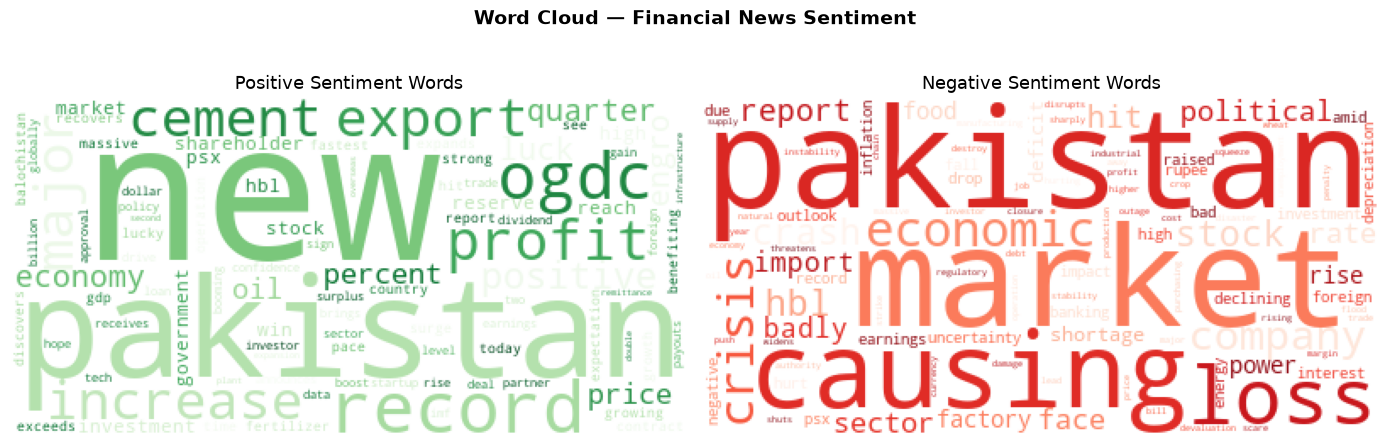

In [13]:

from wordcloud import WordCloud

positive_text = ' '.join(df[df['sentiment']=='positive']['processed_text'])
negative_text = ' '.join(df[df['sentiment']=='negative']['processed_text'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(
    WordCloud(background_color='white', colormap='Greens').generate(positive_text)
)
axes[0].set_title("Positive Sentiment Words", fontsize=13)
axes[0].axis('off')

axes[1].imshow(
    WordCloud(background_color='white', colormap='Reds').generate(negative_text)
)
axes[1].set_title("Negative Sentiment Words", fontsize=13)
axes[1].axis('off')

plt.suptitle("Word Cloud — Financial News Sentiment", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()